In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


In [46]:
# Učitavanje CSV datoteke (pazi da se datoteka nalazi u istoj mapi kao bilježnica)
df = pd.read_csv("student-por.csv", sep=';')

# Prikaz prvih redova
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [47]:
# Pretvaranje svih kategorijalnih varijabli u numeričke (one-hot encoding)
df_encoded = pd.get_dummies(df, drop_first=True)

# Prikaz dimenzija i prvih redova
df_encoded.shape, df_encoded.head()


((649, 42),
    age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
 0   18     4     4           2          2         0       4         3      4   
 1   17     1     1           1          2         0       5         3      3   
 2   15     1     1           1          2         0       4         3      2   
 3   15     4     2           1          3         0       3         2      2   
 4   16     3     3           1          2         0       4         3      2   
 
    Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
 0     1  ...             True           False           True       False   
 1     1  ...            False           False          False        True   
 2     2  ...             True           False           True       False   
 3     1  ...             True           False          False        True   
 4     1  ...            False           False          False        True   
 
    paid_yes  activities_yes  nurser

In [48]:
# Odvajanje X (ulazi) i y (ciljna varijabla)
X = df_encoded.drop('G3', axis=1)
y = df_encoded['G3']


In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [51]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)  # Izlaz za regresiju
])

model.compile(optimizer='adam', loss=tf.keras.losses.MeanSquaredError(), metrics=['mae'])

# Treniranje modela
history = model.fit(X_train_scaled, y_train, epochs=100, batch_size=16, validation_split=0.2, verbose=1)


Epoch 1/100


C:\Users\Jovici\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 143.5020 - mae: 11.4638 - val_loss: 104.5556 - val_mae: 9.9075
Epoch 2/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 85.0967 - mae: 8.7151 - val_loss: 56.0531 - val_mae: 7.0695
Epoch 3/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 44.5789 - mae: 6.1072 - val_loss: 17.1119 - val_mae: 3.5800
Epoch 4/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 13.9039 - mae: 3.0465 - val_loss: 5.3241 - val_mae: 1.7768
Epoch 5/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 6.8802 - mae: 1.8795 - val_loss: 3.8816 - val_mae: 1.4872
Epoch 6/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 5.3766 - mae: 1.6749 - val_loss: 3.4209 - val_mae: 1.4200
Epoch 7/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 3.7649 - mae: 1.4439 - val_loss: 3.0710 - val_mae: 1.3479
Epoch 8/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 4.4464 - mae: 1.4683 - val_loss: 2.8853 - val_mae: 1.3040
Epoch 9/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss

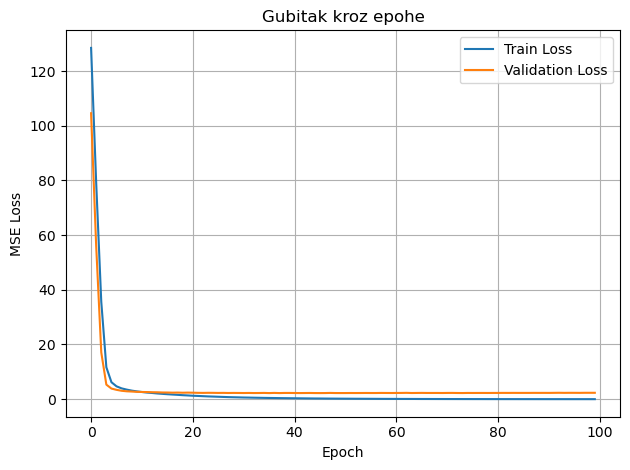

In [52]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Gubitak kroz epohe')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [53]:
# Evaluacija modela
test_loss, test_mae = model.evaluate(X_test_scaled, y_test)
print("Test MAE:", test_mae)

# Predikcija
y_pred_dl = model.predict(X_test_scaled).flatten()


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.5891 - mae: 1.2317 
Test MAE: 1.2303811311721802


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/stepWARNING:tensorflow:5 out of the last 11 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000152B5576200> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step 


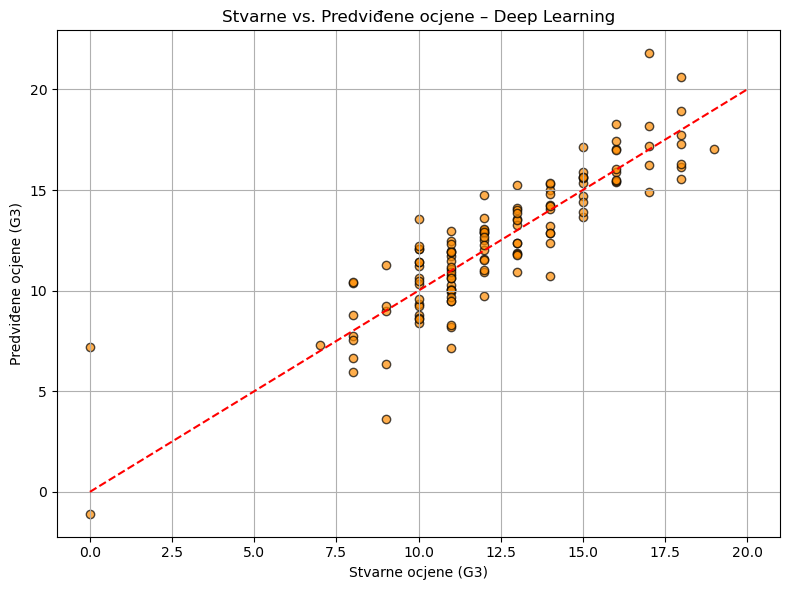

In [54]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_dl, alpha=0.7, color='darkorange', edgecolors='k')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')
plt.xlabel('Stvarne ocjene (G3)')
plt.ylabel('Predviđene ocjene (G3)')
plt.title('Stvarne vs. Predviđene ocjene – Deep Learning')
plt.grid(True)
plt.tight_layout()
plt.show()


In [55]:
# Spremi Keras model u .h5 datoteku
model.save("model_duboko.h5")
